### **Example JIT**: Distance Calculation
Calculate the eucledian distance on two vectors with 5 Mio elements ($d=\sqrt{\sum(a_i-b_i)^2}$).
1. Using native python
2. Using numpy (precompiled functions in C)
3. Using native julia
4. Using native Julia with macros

In [56]:
using Pkg
Pkg.activate(".")
# Pkg.add(["BenchmarkTools", "PythonCall"])
# Pkg.instantiate()

using BenchmarkTools # Package for evaluating execution speed
using PythonCall # Package that allows to call Python from Julia (loads numpy library as specified in CondaPkg.toml)

np = pyimport("numpy");

  Activating project at `c:\Users\timauc002\Documents\GitHub\Julia CMIP`


In [57]:
# Native Python Function (Runs in Python's bytecode interpreter)
@pyexec """
def euclidean_native_py(x, y):
    total = 0.0
    for i in range(len(x)):
        diff = x[i] - y[i]
        total += diff * diff
    return total ** 0.5
""" => euclidean_native_py

# Native Julia Function (Plain loop, JIT-compiled to native CPU machine code)
function euclidean_native_jl(x, y)
    total = 0.0
    for i in eachindex(x, y)
        diff = x[i] - y[i]
        total += diff * diff
    end
    return sqrt(total)
end

# Native Julia Function (Plain loop, JIT-compiled to native CPU machine code)
function euclidean_native_jl_fast(x, y)
    total = 0.0
    # @ is a macro that optimizes the compilation of the loop
    # @inbound tells the compiler to skip bounds checking for array indexing, which can improve performance
    # @simd, Single Instruction, Multiple Data, lets the compiler parallelize the operation
    @inbounds @simd for i in eachindex(x, y)
        diff = x[i] - y[i]
        total += diff * diff
    end
    return sqrt(total)
end;

In [ ]:
# create random array of length N with Float64 values between 0 and 1
N = 1_000_000
a_jl = rand(Float64, N)
b_jl = rand(Float64, N)

# Convert data into Python list and NumPy array formats
a_pylist = pylist(a_jl);       b_pylist = pylist(b_jl);
a_numpy  = np.array(a_jl);     b_numpy  = np.array(b_jl);

# @btime is a macro from BenchmarkTools.jl that measures the execution time of a function call
println("1. Native Python (Interpreted for-loop):")
@btime $euclidean_native_py($a_pylist, $b_pylist)

println("\n2. Python + NumPy (Pre-compiled C library):")
@btime $np.linalg.norm($a_numpy - $b_numpy)

println("\n3. Native Julia (Pure Julia for-loop, JIT compiled):")
@btime euclidean_native_jl($a_jl, $b_jl)

println("\n4. Native Julia (Optimized for-loop, JIT compiled):")
@btime euclidean_native_jl_fast($a_jl, $b_jl);

1. Native Python (Interpreted for-loop):
  620.654 ms (2 allocations: 32 bytes)

2. Python + NumPy (Pre-compiled C library):
  47.933 ms (9 allocations: 176 bytes)

3. Native Julia (Pure Julia for-loop, JIT compiled):
  6.431 ms (0 allocations: 0 bytes)

4. Native Julia (Optimized for-loop, JIT compiled):
  4.100 ms (0 allocations: 0 bytes)


**Things to Notice**
1. **Native Python is slowest**: As expected, the pure Python loop takes the longest because the CPython interpreter has to check variable types and create new float objects in memory on every single iteration.
2. **Native Julia is even faster than NumPy**: even though NumPy also used pre-compiled C code, it is slower than Julia, becuase it evaluates the function `np.linalg.norm(a-b)` in two steps. First it runs the $a-b$ statement and writes it temporarily into RAM (9 allocations), then it runs the NumPy function. This extra step is what makes it slower than Julia which executes everything as a single pass without allocating temporary arrays. 
3. **@inbound and @simd**: both optimization speed up the Julia implementation compared to the basic Julia implementation without macros.
4. **Warm-Up**: The very first time you run a Julia function, there is a brief pause while Julia's JIT compiler translates the code into native machine instructions. The @btime macro excludes this one-time compilation overhead by executing an untimed warm-up run first and then reporting the minimum execution time across multiple runs.

# **Important**: Restart Kernel (if you are in Binder)

### **CMIP Data Analysis**: Climate Stripes
**Packages**
* **Rasters**: Julia package for labeled multidimensional array and geospatial raster manipulation. (like Python xarray)
* **NCDatasets**: Reading, writing, and inspecting NetCDF files.
* **Dates**: Handling calendar dates, timestamps, and time intervals.
* **Statistics**: Statistical operations like `mean` and `std`.
* **CairoMakie**: Visualizing data.
* **GeoMakie**: Cartographic extension for Makie.

In [ ]:
# Pkg.add(["Rasters", "NCDatasets", "Dates", "Statistics"])
# Pkg.add(["CairoMakie", "GeoMakie"])
# YAXArray.jl other library for processing these data in Julia

using Rasters, Dates, Statistics, NCDatasets, PythonCall
using CairoMakie, GeoMakie

#### Load Data

In [60]:
intake_esgf = pyimport("intake_esgf")

# Search and download (reuses the files in ~/.esgf if already there)
catalog = intake_esgf.ESGFCatalog()     # don't call this `cat`: it would hide Julia's cat()
catalog.search(
    project       = "CMIP6",
    experiment_id = pylist(["historical", "ssp585"]),
    source_id     = "ACCESS-CM2",
    variable_id   = "tas",
    frequency     = "mon",
    variant_label = "r1i1p1f1",
    file_end      = "2100-12",
)
paths = catalog.to_path_dict()

# Convert to a Julia Dict: "historical" => [file, ...], "ssp585" => [file, ...]
# (Python keys look like "CMIP.historical", so keep only the part after the dot)
files = Dict(
    pyconvert(String, k.split(".")[-1]) => [pyconvert(String, pystr(p)) for p in v]
    for (k, v) in paths.items())

loadtas(fs) = cat([read(Raster(f; name=:tas, lazy=true)[Ti=Where(t -> 1979 <= year(t) <= 2025)])
                   for f in fs]...; dims=Ti)
hist = modify(Array{Float32}, loadtas(files["historical"]))
ssp  = modify(Array{Float32}, loadtas(files["ssp585"]))
tas_raw = cat(hist, ssp; dims=Ti)

Searching indices ---------------------------------------- 100% 0:00:01
Get file information ---------------------------------------- 100% 0:00:00


c:\Users\timauc002\Documents\GitHub\Julia CMIP\.CondaPkg\.pixi\envs\default\Lib\site-packages\intake_esgf\catalog.py:936: UserWarning: You are searching for project='CMIP6' with at least one STAC-based index enabled. While republishing CMIP6 data to STAC is underway and may work well, we have found a publishing error that affects many records. You may see some unexpected `member_id` fields. Temporarily, we recommend disabling these indices for work with CMIP6:
intake_esgf.conf.set(indices={'discovery.east.esgf.io':False,'discovery.west.esgf.io': False})
  warnings.warn(


┌ 192×144×564 Raster{Float32, 3} tas ┐
├────────────────────────────────────┴─────────────────────────────────── dims ┐
  ↓ X Mapped{Float64} 0.9375:1.875:359.0625 ForwardOrdered Regular Intervals{Center},
  → Y Mapped{Float64} -89.375:1.25:89.375 ForwardOrdered Regular Intervals{Center},
  ↗ Ti Sampled{DateTime} [DateTime("1979-01-16T12:00:00"), …, DateTime("2025-12-16T12:00:00")] ForwardOrdered Explicit Intervals{Center}
├──────────────────────────────────────────────────────────────────── metadata ┤
  Metadata{Rasters.NCDsource} of Dict{String, Any} with 10 entries:
  "cell_methods"  => "area: time: mean"
  "coordinates"   => "height"
  "_FillValue"    => 1.0f20
  "missing_value" => 1.0f20
  "standard_name" => "air_temperature"
  "long_name"     => "Near-Surface Air Temperature"
  "units"         => "K"
  "history"       => "2019-11-08T06:41:45Z altered by CMOR: Treated scalar dime…
  "comment"       => "near-surface (usually, 2 meter) air temperature"
  "cell_measures" => "area: ar

#### Calculate Temperature Anomaly

In [61]:
tas = tas_raw .- 273.15f0
    
# Slice periods using precise end dates to ensure perfect 12-month multiples
tas_ref = tas[Ti(Where(x -> 1981 <= Dates.year(x) <= 2010))]
tas_anal = tas[Ti(Where(x -> 1979 <= Dates.year(x) <= 2025))]

nx, ny, nt_ref = size(tas_ref) # dimensions of reference period
nt_anal = size(tas_anal, 3) # time dimension of analysis period

# Reshape (Julia Base) the 3D reference array into 4D: (X, Y, Month, Year)
ref_reshaped = reshape(tas_ref.data, nx, ny, 12, nt_ref ÷ 12) # ÷ use for integer division

# Take mean across the year dimension (192, 144, 12, 1)
clim_data = mean(ref_reshaped, dims=4)

# Reshape the analysis array to match the 4D structure
anal_reshaped = reshape(tas_anal.data, nx, ny, 12, nt_anal ÷ 12)

# Subtract the monthly climatology
anal_data = anal_reshaped .- clim_data; # dim (192, 144, 12, 36) .- (192, 144, 12, 1)

# Convert back into raster file
anal_data = Raster(reshape(anal_data, nx, ny, nt_anal), dims(tas_anal))
mean_anal = mean(anal_data, dims=Ti)

┌ 192×144×1 Raster{Float32, 3} ┐
├──────────────────────────────┴───────────────────────────────────────── dims ┐
  ↓ X Mapped{Float64} 0.9375:1.875:359.0625 ForwardOrdered Regular Intervals{Center},
  → Y Mapped{Float64} -89.375:1.25:89.375 ForwardOrdered Regular Intervals{Center},
  ↗ Ti Sampled{DateTime} DateTime("2002-07-02T12:00:00"):Millisecond(2678400000):DateTime("2002-07-02T12:00:00") ForwardOrdered Explicit Intervals{Center}
├────────────────────────────────────────────────────────────────────── raster ┤
  extent: Extent(X = (0.0, 360.0), Y = (-90.0, 90.0), Ti = (DateTime("1979-01-01T00:00:00"), DateTime("2026-01-01T00:00:00")))
  crs: EPSG:4326
  mappedcrs: EPSG:4326
└──────────────────────────────────────────────────────────────────────────────┘
[:, :, 1]
   ↓ →     -89.375     -88.125     …  86.875     88.125     89.375
   0.9375    0.275573    0.318173      0.792436   0.768628   0.757774
   2.8125    0.274984    0.321145      0.79037    0.766226   0.756359
   4.6875    0.

#### Visualization Average Anomaly in Space

In [62]:
# Remove dimensions for plotting
data_matrix = dropdims(mean_anal, dims=Ti).data

# Extract coordinates and data and convert into native julia arrays
lons = collect(lookup(tas_anal, X))
lats = collect(lookup(tas_anal, Y))

# Shift longitudes from [0, 360] to [-180, 180] for GeoMakie Robinson projection
split_idx = findfirst(x -> x > 180, lons)
lons_shifted = vcat(lons[split_idx:end] .- 360, lons[1:split_idx-1])
data_shifted = vcat(data_matrix[split_idx:end, :], data_matrix[1:split_idx-1, :]);

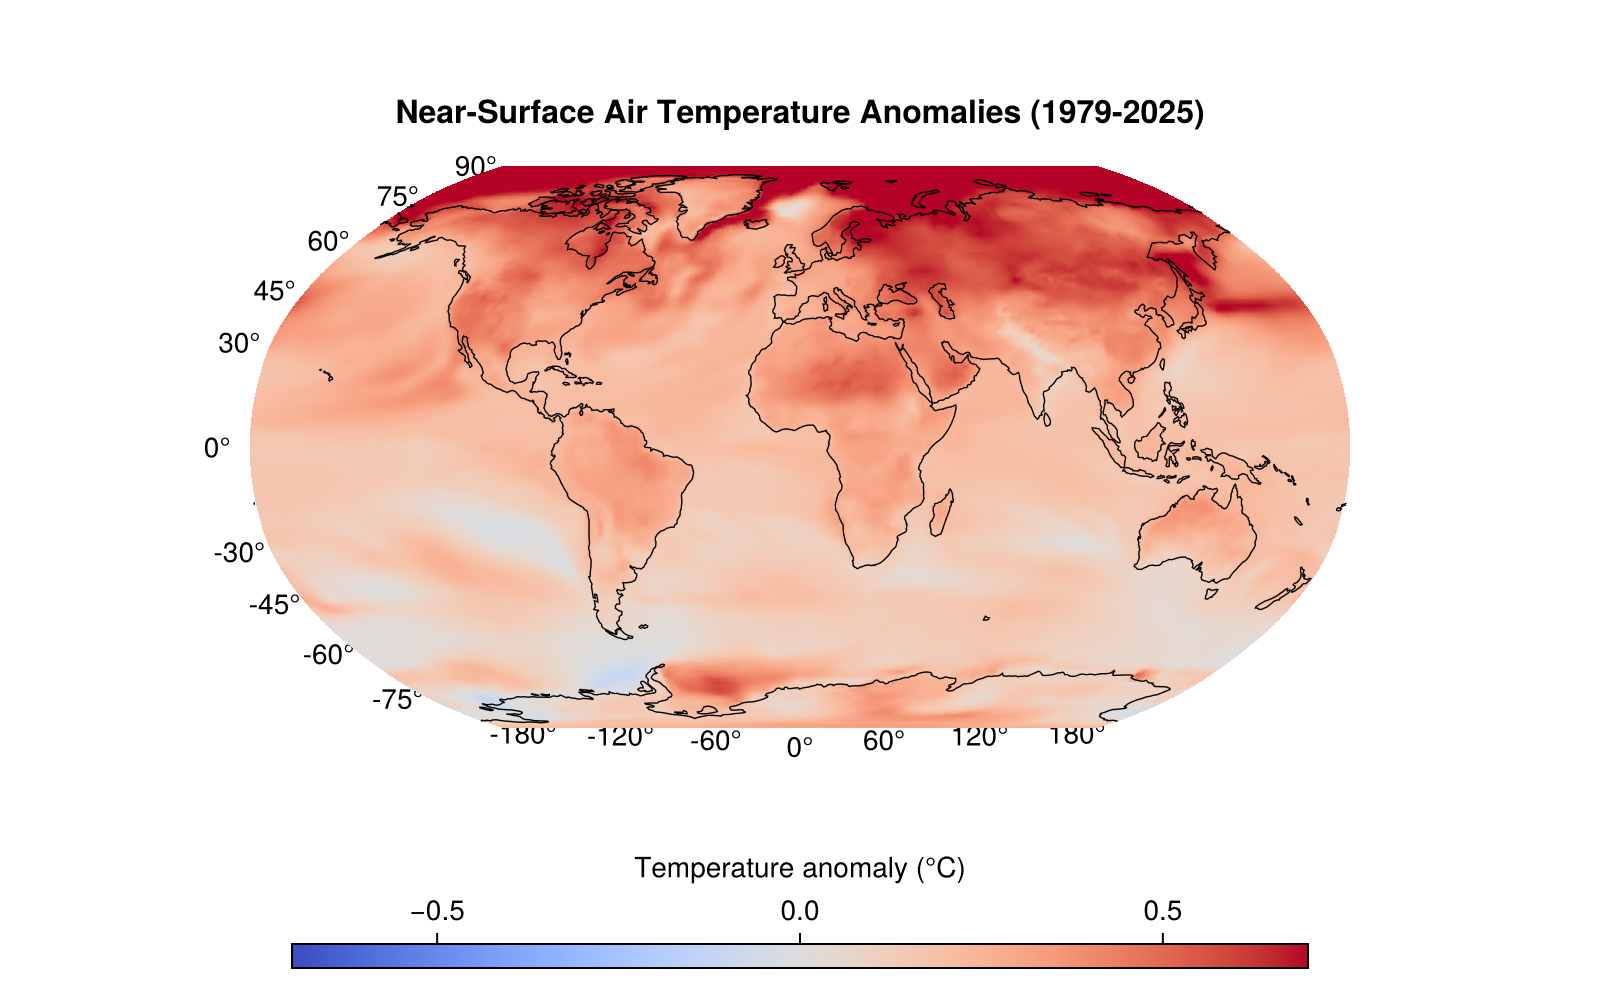

In [63]:
# Create Figure with standard Greenwich-centered projection
fig = Figure(size = (800, 500))
ga = GeoAxis( # create geographic coordinate system
    fig[1, 1];
    dest = "+proj=robin", # Robinson projection (Edges are now strictly ±180°) 
    title = "Near-Surface Air Temperature Anomalies (1979-2025)",
    titlesize = 16,
    xgridvisible = false, # hide grid lines
    ygridvisible = false
)
# Plot the surface using the shifted longitudes and data
sp = surface!(
    ga, # projection from Geoaxis
    lons_shifted, 
    lats, 
    data_shifted;
    colormap = :coolwarm,
    colorrange = (-0.7, 0.7),
    shading = NoShading
)

# add coastlines
lines!(ga, GeoMakie.coastlines(), color = :black, linewidth = 0.7)

# Add horizontal colorbar
Colorbar(
    fig[2, 1], sp; 
    vertical = false, 
    label = "Temperature anomaly (°C)", 
    width = Relative(0.7)
)

fig

#### Visualization Polar Amplification

In [65]:
# Plot temperature curve of arctiv region
# Select latitudes 65-90°N and average over lon (X) and lat (Y)
tas_65_90N = anal_data[Y(65 .. 90)]
tas_65_90N_mean = mean(tas_65_90N, dims=(X, Y))
tas_65_90N_mean = dropdims(tas_65_90N_mean, dims=(X, Y));

time_data = collect(lookup(tas_65_90N_mean, Ti)); # Extract a standard array from the Raster data
temp_data_65_90N = collect(tas_65_90N_mean); # Extract a standard array from the Raster data


In [ ]:
# Do the same from 30 to 65
# tas_30_60N_mean = mean(anal_data[Y(30 .. 65)], dims=(X, Y))
# tas_30_60N_mean = dropdims(tas_30_60N_mean, dims=(X, Y))
# temp_data_30_60N = collect(tas_30_60N_mean);

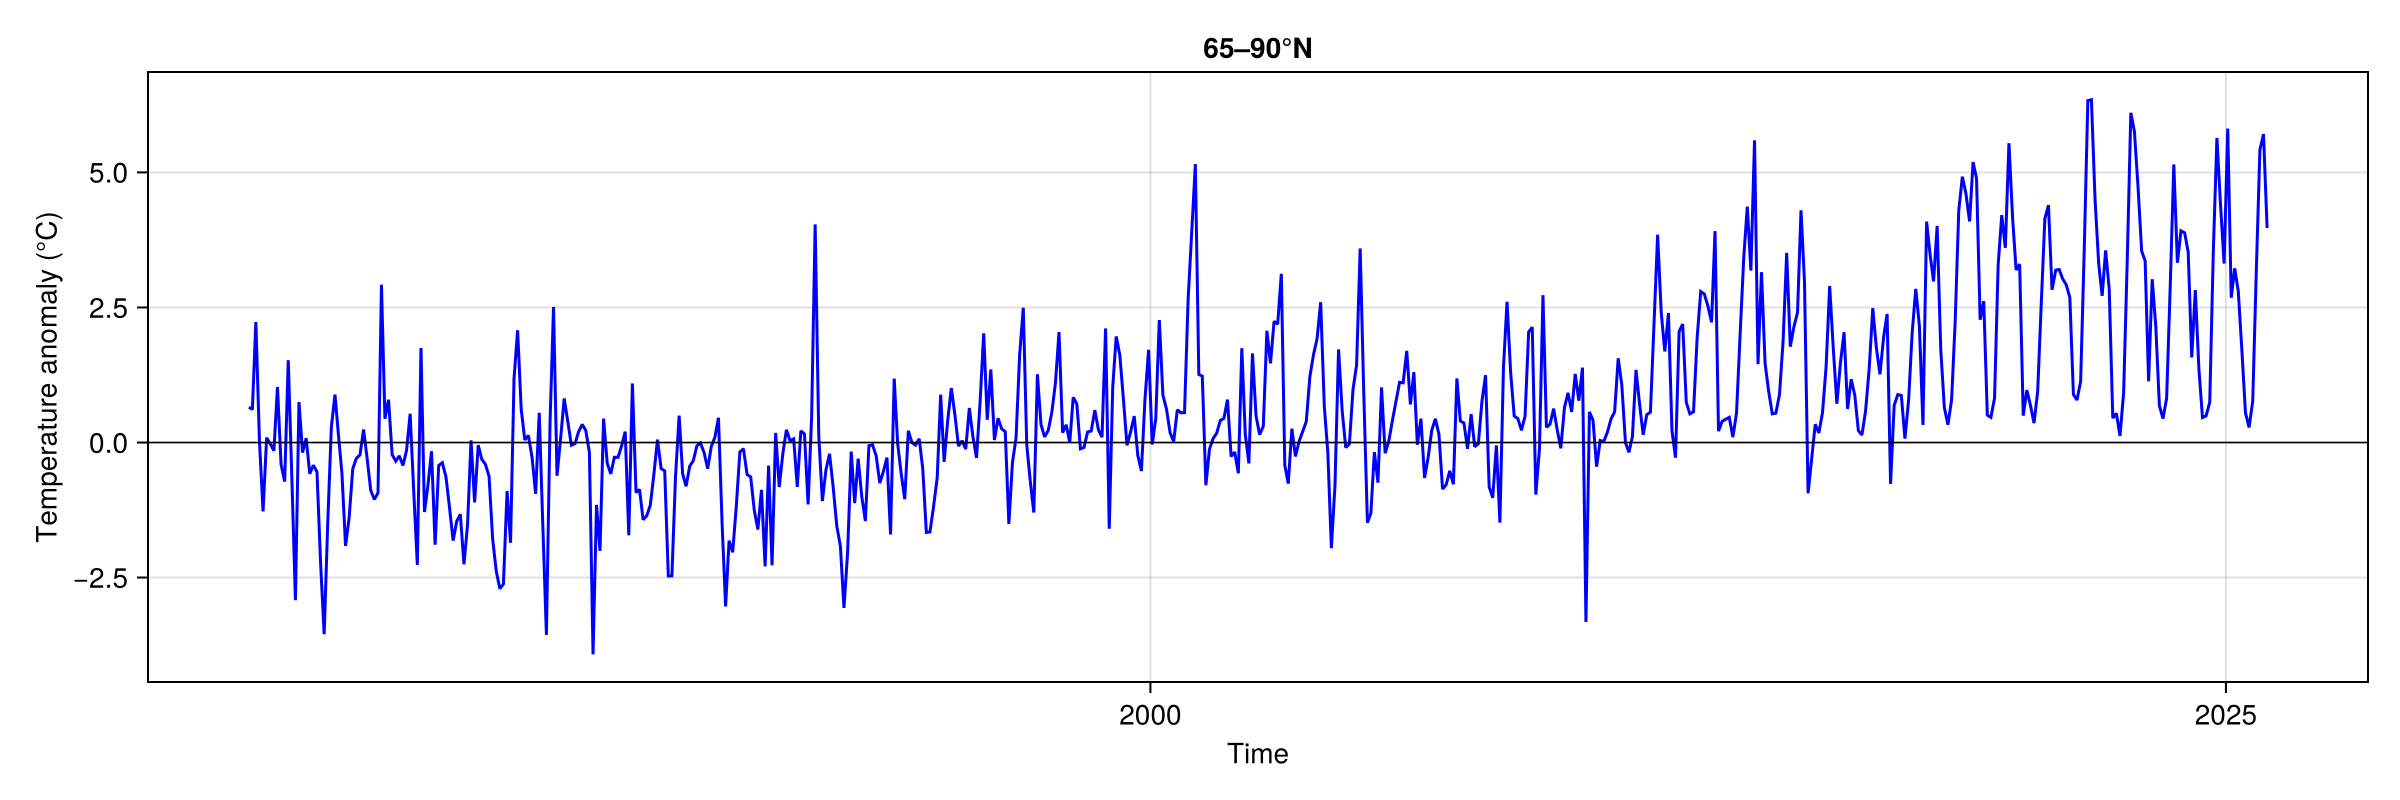

In [66]:
fig = Figure(size = (1200, 400)) # create figure canvas

# Create the first Axis in row 1, column 1 (Left)
ax1 = Axis( 
    fig[1, 1], 
    xlabel = "Time",
    ylabel = "Temperature anomaly (°C)",
    title = "65–90°N"
)

# Create the second Axis in row 1, column 2 (Right)
# ax2 = Axis(
#     fig[1, 2], 
#     xlabel = "Time",
#     title = "30–65°N"
# )

# Plot data into the first axis
lines!(ax1, time_data, temp_data_65_90N, color = :blue, linewidth = 1.5)
hlines!(ax1, [0.0], color = :black, linewidth = 0.8)

# Plot data into the second axis
# lines!(ax2, time_data, temp_data_30_60N, color = :red, linewidth = 1.5)
# hlines!(ax2, [0.0], color = :black, linewidth = 0.8)

# linkyaxes!(ax1, ax2) # sync the y-axis of all plots
display(fig);

##### Visualize Climate Stripes

In [67]:
# Group time variable into years
temp_grouped = groupby(tas_65_90N, Ti => Dates.year)

┌ 47-element DimGroupByArray{Raster{Float32,3},1} ┐
├─────────────────────────────────────────────────┴─────────────── dims ┐
  ↓ Ti Sampled{Int64} [1979, …, 2025] ForwardOrdered Irregular Points
├───────────────────────────────────────────────────────────── metadata ┤
  Dict{Symbol, Any} with 1 entry:
  :groupby => :Ti=>year
├─────────────────────────────────────────────────┴───────── group dims ┐
  ↓ X, → Y, ↗ Ti
└───────────────────────────────────────────────────────────────────────┘
 1979  192×20×12 Raster
 1980  192×20×12 Raster
    ⋮  
 2025  192×20×12 Raster

In [68]:
temperature = mean.(temp_grouped)

┌ 47-element DimArray{Float32, 1} ┐
├─────────────────────────────────┴─────────────────────────────── dims ┐
  ↓ Ti Sampled{Int64} [1979, …, 2025] ForwardOrdered Irregular Points
└───────────────────────────────────────────────────────────────────────┘
 1979   0.298601
 1980  -0.95514
 1981  -0.489437
 1982  -0.0674735
 1983  -0.802693
    ⋮  
 2021   3.21668
 2022   2.86832
 2023   2.53557
 2024   2.64721
 2025   3.00792

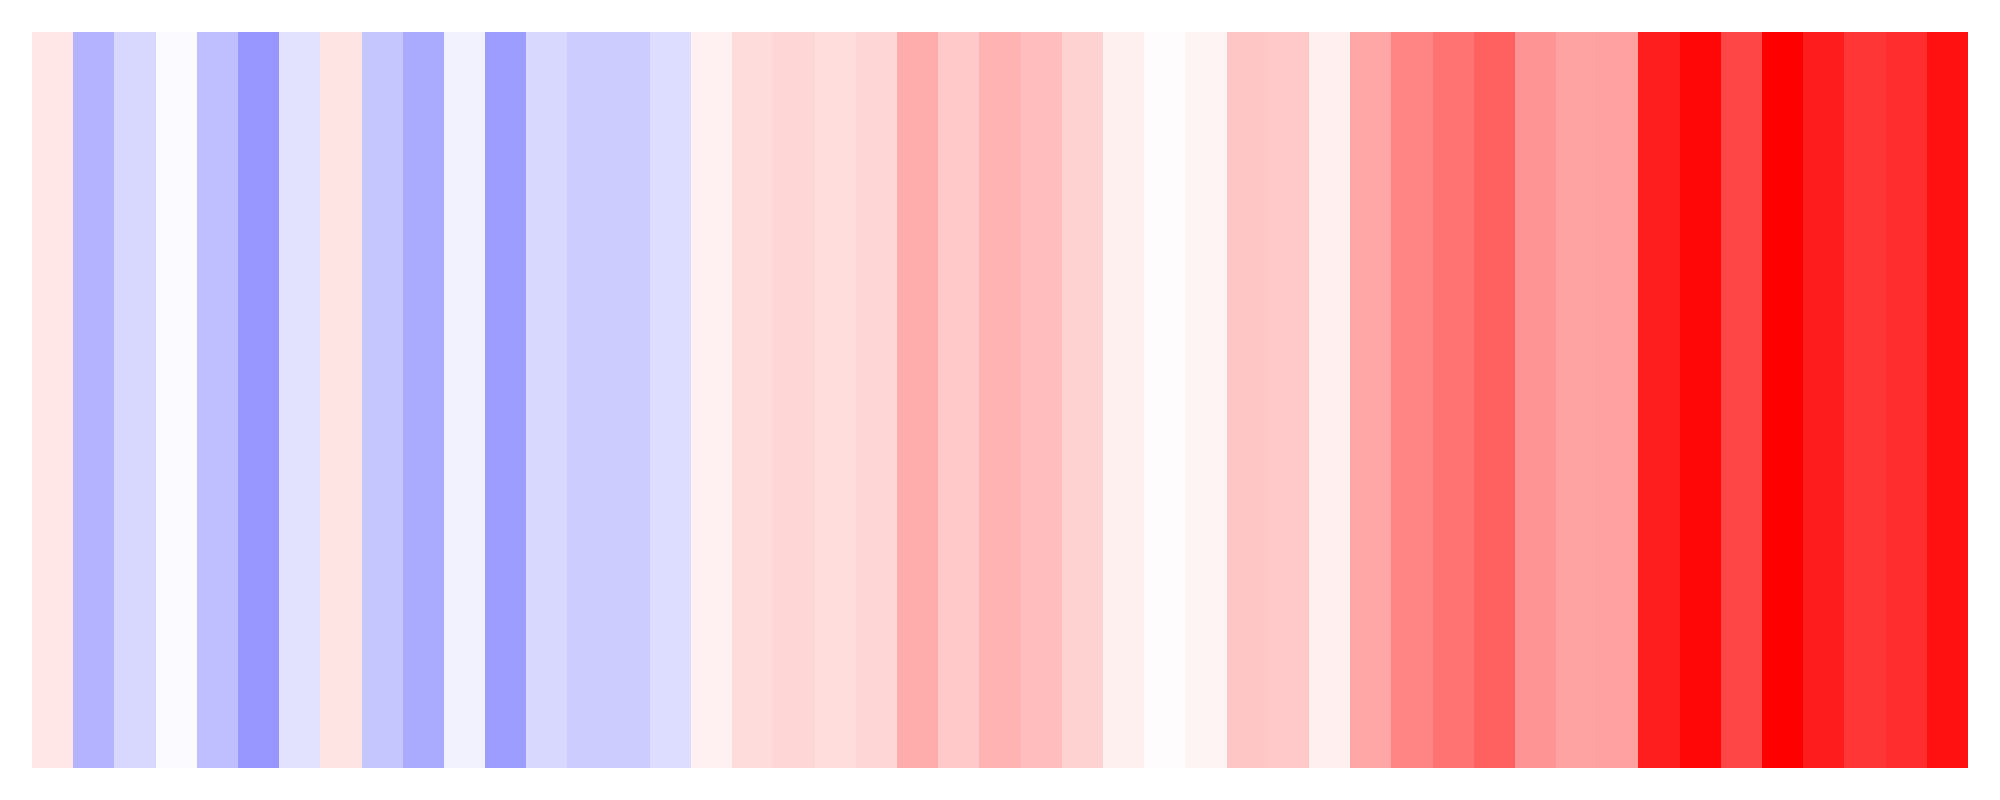

In [69]:
years = collect(lookup(temperature, Ti)) # Extract the numeric years directly from the grouped Raster
temp_values = collect(temperature) # Extract the numeric temperature values

# Get the maximum absolute anomaly for a centered color scale
limit = maximum(abs.(temp_values))

fig = Figure(size = (1000, 400))
ax = Axis(fig[1, 1])

# Remove standard plot elements
hidedecorations!(ax) # remove x and y labels
hidespines!(ax)  # remove x and y axis lines

heatmap!(
    ax, 
    years, 
    [1], # y-axis dummy value
    reshape(temp_values, :, 1); # Reshape 1D vector to an (N_years, 1) matrix
    colormap = :bwr,
    colorrange = (-limit, limit)
)

display(fig);